# OH NO

A virus is coming where 50% of the these little figures will have contracted a disease where they get a white spot. The code below generates the disease data. Your job is as follows

1. Generate the data as below
2. Train a convolutional neural network to classify patient images as diseased or not
   1. Create training and validation sets.
   2. Contrast in the sensitivity, specificity and accuracy in both sets.

In [1]:
import tensorflow as tf
print(tf.__version__)

import urllib.request
import PIL
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers, models, losses
from sklearn.model_selection import train_test_split

2.21.0


In [2]:
## Open the image
imgURL = "https://raw.githubusercontent.com/larvalabs/cryptopunks/master/punks.png"
urllib.request.urlretrieve(imgURL, "cryptoPunksAll.jpg")
img = PIL.Image.open("cryptoPunksAll.jpg").convert("RGB")
imgArray = np.asarray(img)

n = 10000

finalArray = np.empty((n, 24, 24, 3))
for i in range(100):
  for j in range(100):
    a, b = 24 * i, 24 * (i + 1)
    c, d = 24 * j, 24 * (j + 1)
    idx = j + i * (100)
    finalArray[idx,:,:,:] = imgArray[a:b,c:d,:]

Our doctors have determined this is the region where the lesion occurs.

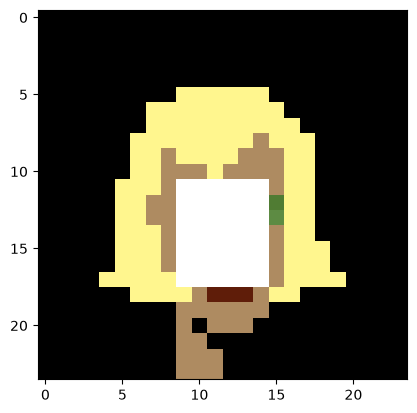

In [3]:
temp  =  finalArray[0,:,:,:].copy()
d2min, d2max = 9,14
d1min, d1max = 11,17
temp[d1min : (d1max + 1), d2min : (d2max + 1)] = 255

plt.imshow(temp.astype('uint8'))

In [4]:
# seed the random data generation so I'm working with the same dataset
np.random.seed(58577181)

cancerpunks = finalArray.copy()
label = np.zeros(n)

## Loop over the cryptopunks
for i in range(10000):
  flip = np.random.randint(0, 2)
  if flip == 1:
    label[i] = 1
    d1loc = np.random.randint(d1min, d1max + 1)
    d2loc = np.random.randint(d2min, d2max + 1)
    cancerpunks[i,d1loc,d2loc,:] = 255

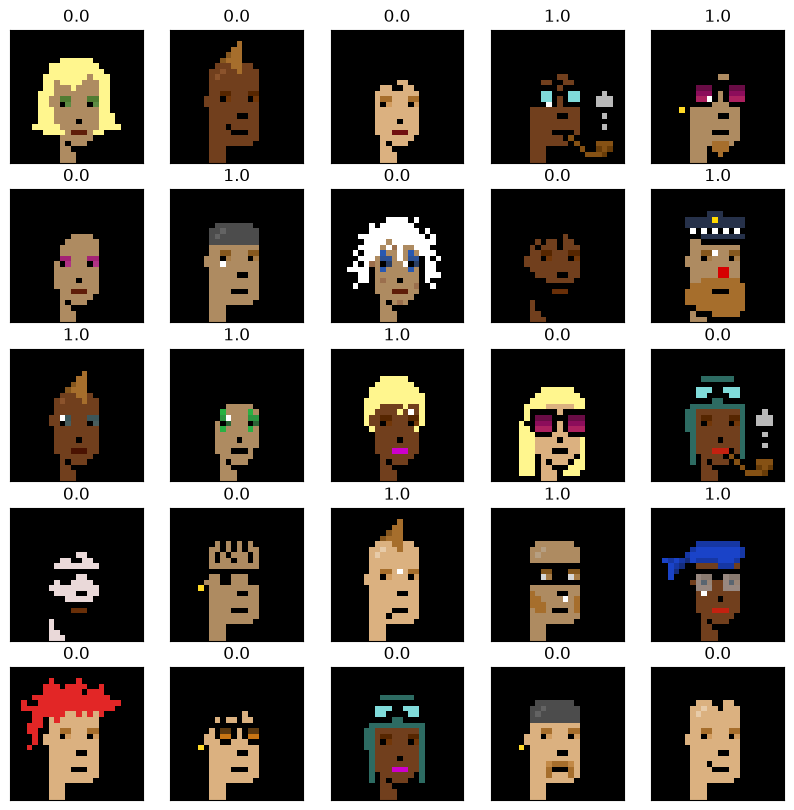

In [5]:
## plot some examples
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(cancerpunks[i,:,:,:].astype('uint8'))
  plt.title(label[i])

# Solution

First let's do a quick check that the dataset was generated properly.

In [6]:
print("cancerpunks.shape:", cancerpunks.shape)
print("label.shape:", label.shape)
print("total diseased:", (label == 1).sum())

cancerpunks.shape: (10000, 24, 24, 3)
label.shape: (10000,)
total diseased: 4942


Let's split the data in train/test and normalize the pixel values

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

n = cancerpunks.shape[0]
trainFraction = .75
sample = np.random.uniform(size = n) < trainFraction
x_train = cancerpunks[sample, :, :, :].transpose(0, 3, 1, 2) / 255
x_test = cancerpunks[~sample, :, :, :].transpose(0, 3, 1, 2) / 255

y_train = label[sample]
y_test = label[~sample]
## Need to have the extra dimension
y_train = y_train.reshape(y_train.shape[0], 1)
y_test = y_test.reshape(y_test.shape[0], 1)

y_train = torch.Tensor(y_train).to(device)
x_train = torch.Tensor(x_train).to(device)
trainDataset = TensorDataset(x_train, y_train)
# trainloader = torch.utils.data.DataLoader(trainDataset, batch_size = 100, shuffle = False, num_workers = 0)
trainloader = torch.utils.data.DataLoader(trainDataset, batch_size = 100, shuffle = True, num_workers = 0)

Next build the CNN 

In [8]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 3 * 3, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

def build_cnn(learning_rate):
    net = Net().to(device)
    criterion = nn.BCELoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)
    return net, criterion, optimizer

In [9]:
net, criterion, optimizer = build_cnn(0.001)

Then we will train the network

In [10]:
def train(trainloader, criterion, optimizer, epochs):
    for epoch in range(epochs):  # loop over the dataset multiple times
        running_loss = 0.0
        for i, data in enumerate(trainloader, 0):
            # get the inputs; data is a list of [inputs, labels]
            inputs, labels = data
    
            # zero the parameter gradients
            optimizer.zero_grad()
    
            # forward + backward + optimize
            outputs = net(inputs)
    
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    print("Finished training")

train(trainloader, criterion, optimizer, 100)

Finished training


In [11]:
def evaluate_model(net):
    net.eval()
    for name, x, y in [
        ("Training", x_train, y_train),
        ("Validation", torch.Tensor(x_test).to(device), torch.Tensor(y_test).to(device))
    ]:
        with torch.no_grad():
            predicted = (net(x) >= 0.5).float()
        tp = ((predicted == 1) & (y == 1)).sum().item()
        tn = ((predicted == 0) & (y == 0)).sum().item()
        fp = ((predicted == 1) & (y == 0)).sum().item()
        fn = ((predicted == 0) & (y == 1)).sum().item()
    
        print(name)
        print("Sensitivity:", round(tp / (tp + fn), 3))
        print("Specificity:", round(tn / (tn + fp), 3))
        print("Accuracy:", round((tp + tn) / (tp + tn + fp + fn), 3))

evaluate_model(net)

Training
Sensitivity: 0.005
Specificity: 0.997
Accuracy: 0.508
Validation
Sensitivity: 0.004
Specificity: 0.998
Accuracy: 0.503


This is pretty poor accuracy. Sensitivity is low and specificity is high so it seems like my model is predicting too often that images have no tumor. Let's increase the learning rate to make bigger adjustments while learning to see if that helps.

In [12]:
net, criterion, optimizer = build_cnn(0.005)
train(trainloader, criterion, optimizer, 100)
evaluate_model(net)

Finished training
Training
Sensitivity: 0.997
Specificity: 0.999
Accuracy: 0.998
Validation
Sensitivity: 0.993
Specificity: 0.998
Accuracy: 0.996


This is much better! Our model now correctly diagnoses nearly all cases. It performed slightly better in the training set than in the test set, but this does not appear to be a case of overfitting since accuracy is already above 99% in the test set. Sensitivity, specificity, and accuracy are about the same in both sets.

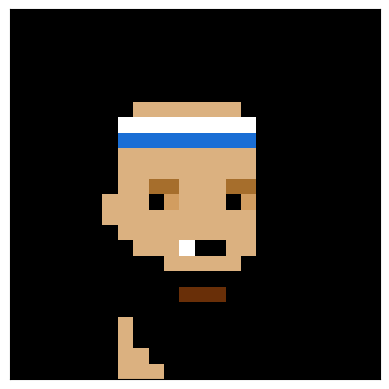

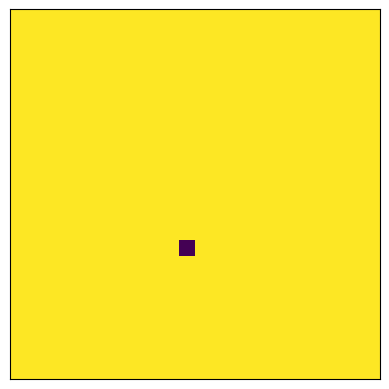

In [13]:
# Pick the picture with the highest predicted chance of disease.
with torch.no_grad():
    testout = net(torch.Tensor(x_test).to(device)).cpu().numpy()
image = x_test[np.argmax(testout)]
plt.imshow(np.transpose(image, (1, 2, 0)))
plt.xticks([])
plt.yticks([])
plt.show()

xdim = image.shape[1]
ydim = image.shape[2]
probmap = np.empty([xdim, ydim])
net.to(torch.device("cpu"))
with torch.no_grad():
    for i in range(xdim):
        for j in range(ydim):
            temp = image.copy()
            temp[0, i, j] = 0
            temp[1, i, j] = 0
            temp[2, i, j] = 0
            ## add an extra row
            temp = temp[np.newaxis, :, :, :]
            probmap[i,j] = net(torch.Tensor(temp)).item()

plt.imshow(probmap)
plt.xticks([])
plt.yticks([])
plt.show()